# HW4 V1 · Ridge stock selection and backtest

## 1. Setup

- `Starting capital`:	$1,000,000; long only; no borrowing or leverage
- `Entries`: Any trading day, at the close; decisions must be made before that fill price is known
- `Holding period`: Hold each purchase for 90 calendar days; sell at the close on maturity, or the next market session if closed
- `Purchase`: Purchases consume available cash; sales return cash. Never spend the same cash twice
- `Test`: Include the value of open positions on Sep 30, 2026; do not use later prices


In [1]:
from dataclasses import dataclass
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

START = "2016-04-01"
END = "2026-09-30"
CAPITAL = 1_000_000
FEE = 0.0005
TOP_N = 10
FEATURES = ["return_5", "return_10", "return_21", "return_63", "return_252_skip_21", "volatility_63"]

## 2. Load market data

- `benchmark`: SP500, date, adj_closed_price
- `prices`: symbol, date, adj_closed_price
- `members`: symbol, quarter_start, selection_date

In [2]:
def load_market(database):
    with duckdb.connect(str(database), read_only=True, config={"threads": 2}) as con:
        benchmark = con.execute("""
            SELECT date, adj_close FROM benchmark
            WHERE date BETWEEN '2008-01-01' AND ?
            ORDER BY date
        """, [END]).df().set_index("date").adj_close
        prices = con.execute("""
            SELECT symbol, date, adj_close FROM prices
            WHERE date BETWEEN '2008-01-01' AND ?
              AND isfinite(adj_close) AND adj_close > 0
        """, [END]).df()
        members = con.execute("""
            SELECT symbol, quarter_start, selection_date FROM universe_membership
            WHERE quarter_start BETWEEN '2010-01-01' AND ?
        """, [END]).df()
    benchmark.index = pd.DatetimeIndex(benchmark.index)
    assert benchmark.index.is_unique and benchmark.gt(0).all()
    quotes = prices.pivot(index="date", columns="symbol", values="adj_close")
    return quotes.reindex(benchmark.index), benchmark, members

# Find the course repository and use the script’s default database.
cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / "Lectures/modeling/data").is_dir()), None)
if root is None:
    root = Path.home() / "Desktop/dev/ucb-mfe/UCB-MFE-python-preprogram-2026-winter"
database = root / "Lectures/modeling/data/equities_top2000.duckdb"
quotes, benchmark, members = load_market(database)
quotes.iloc[:5, :6]


Out[1]: 
symbol          A     AA  AAC  AADI       AAIC        AAL
date                                                     
2008-01-02  22.97  66.96  NaN   NaN  15.042658  12.557314
2008-01-03  22.74  67.08  NaN   NaN  15.428366  11.991673
2008-01-04  22.00  64.63  NaN   NaN  14.608736  11.699422
2008-01-07  22.36  61.37  NaN   NaN  15.621223  11.529727
2008-01-08  22.33  57.45  NaN   NaN  14.946228  10.379583


In [3]:
benchmark.head()

Out[1]: 
date
2008-01-02    2273.41
2008-01-03    2273.41
2008-01-04    2217.59
2008-01-07    2224.76
2008-01-08    2184.67
Name: adj_close, dtype: float64


In [4]:
members.head()

Out[1]: 
  symbol quarter_start selection_date
0   TSYS    2010-01-01     2009-12-31
1   APDN    2010-01-01     2009-12-31
2    XOM    2010-01-01     2009-12-31
3   PEGY    2010-01-01     2009-12-31
4   MSFT    2010-01-01     2009-12-31


## 3. Features and 90-day data preparation

In [5]:
def monthly_features(values, daily, symbols, signal):
    return pd.DataFrame(
        {
            "return_5": values[signal] / values[signal - 5] - 1,
            "return_10": values[signal] / values[signal - 10] - 1,
            "return_21": values[signal] / values[signal - 21] - 1,
            "return_63": values[signal] / values[signal - 63] - 1,
            "return_252_skip_21": values[signal - 21] / values[signal - 252] - 1,
            "volatility_63": daily.iloc[signal - 62 : signal + 1]
            .std(skipna=False)
            .to_numpy(),
        },
        index=symbols,
    )

In [6]:
def add_return_labels(panel, quotes, entry, exit_row):
    panel["label_end"] = pd.NaT
    panel["target"] = np.nan

    entry_price = quotes.iloc[entry].reindex(panel.index)
    dates = quotes.index

    for row in range(exit_row, min(exit_row + 6, len(dates))):
        exit_price = quotes.iloc[row].reindex(panel.index)
        valid = panel["target"].isna() & entry_price.notna() & exit_price.notna()

        panel.loc[valid, "label_end"] = dates[row]
        panel.loc[valid, "target"] = exit_price[valid] / entry_price[valid] - 1

    return panel

In [7]:
def monthly_panel(quotes, members):
    dates = quotes.index
    months = dates.to_period("M")

    # purchase after signal date, and hold for 90 days. The signal date is the last day of the month.
    entries = np.flatnonzero(months[1:] != months[:-1]) + 1
    entries = entries[dates[entries] >= "2010-01-01"]
    signals = entries - 1
    exit_rows = dates.searchsorted(dates[entries] + pd.Timedelta(days=90))

    daily = quotes.pct_change(fill_method=None)
    values = quotes.to_numpy()
    parts = []

    for entry, signal, exit_row in zip(entries, signals, exit_rows):
        if signal < 252:
            continue

        signal_date = dates[signal]
        entry_date = dates[entry]
        quarter = entry_date.to_period("Q").start_time

        # Select the eligible symbols for the current quarter and signal date
        eligible = members.loc[
            members["quarter_start"].eq(quarter)
            & members["selection_date"].le(signal_date),
            "symbol",
        ]

        panel = monthly_features(values, daily, quotes.columns, signal)
        panel = panel.loc[panel.index.isin(eligible)]
        panel = panel.replace([np.inf, -np.inf], np.nan)
        panel = panel.dropna(subset=FEATURES)

        panel["signal"] = signal_date
        panel["entry"] = entry_date
        panel = add_return_labels(panel, quotes, entry, exit_row)

        parts.append(panel.reset_index())

    return pd.concat(parts, ignore_index=True)

In [8]:
panel = monthly_panel(quotes, members)
panel.head()

Out[1]: 
  symbol  return_5  return_10  ...      entry  label_end    target
0      A  0.025026   0.043524  ... 2010-01-04 2010-04-05  0.112626
1   AAIC -0.029318  -0.014239  ... 2010-01-04 2010-04-05  0.167964
2    AAL -0.063829   0.012552  ... 2010-01-04 2010-04-05  0.494759
3   AAON -0.008798   0.011976  ... 2010-01-04 2010-04-05  0.155620
4    AAP -0.021384  -0.004294  ... 2010-01-04 2010-04-05  0.058230

[5 rows x 11 columns]


## 4. Fit, validate and rank
Features must use information available when the prediction is made. At every fit, use only targets whose holding periods have already ended. This still matters after the buffer. Fit any learned preprocessing on training data only. Do not remove stocks because you know they later disappear.

In [9]:
def select_ridge_alpha(development):
    # Fit each fold using only return labels available before validation.
    scores = {}
    validation_rows = []
    for alpha in (1, 100, 1000):
        errors = []
        for year in (2013, 2014, 2015):
            cutoff = pd.Timestamp(year=year, month=1, day=1)
            train = development.loc[development.label_end.lt(cutoff)]
            valid = development.loc[
                development.signal.dt.year.eq(year)
                & development.label_end.lt("2016-01-01")
            ]
            assert train.label_end.max() < valid.signal.min()
            model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
            model.fit(train[FEATURES], train.target)
            predicted = model.predict(valid[FEATURES])
            rmse = np.sqrt(np.mean((predicted - valid.target) ** 2))
            errors.append(rmse)
            ridge = model.named_steps["ridge"]
            validation_rows.append({
                "alpha": alpha,
                "validation_year": year,
                "training_rows": len(train),
                "validation_rows": len(valid),
                "rmse": rmse,
                "intercept": ridge.intercept_,
                **dict(zip(FEATURES, ridge.coef_)),
            })
        scores[alpha] = np.mean(errors)
    return min(scores, key=scores.get), scores, pd.DataFrame(validation_rows)


In [10]:
def rank_test_stocks(model, test):
    # Rank candidates by predicted return within each entry date.
    test["score"] = model.predict(test[FEATURES])
    ranked = test.sort_values(["entry", "score", "symbol"], ascending=[True, False, True])
    picks = {date: list(group.symbol.head(TOP_N)) for date, group in ranked.groupby("entry")}
    return picks


In [11]:
def development_samples(panel):
    return panel.loc[
        panel.signal.between("2010-01-01", "2015-12-31") & panel.entry.lt("2016-01-01")
        & panel.label_end.lt(START)
    ]


def fit_and_rank(panel):
    development = development_samples(panel)
    alpha, scores, validation_results = select_ridge_alpha(development)
    # Refit the selected setting on all eligible development samples.
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(development[FEATURES], development.target)
    test = panel.loc[panel.entry.between(START, END)].copy()
    assert development.label_end.max() <= test.signal.min()
    assert test.signal.lt(test.entry).all()
    picks = rank_test_stocks(model, test)
    return picks, scores, alpha, len(development), development.label_end.max(), validation_results, model


In [12]:
picks, errors, alpha, rows, last_label, validation_results, final_model = fit_and_rank(panel)
print("Development validation RMSE and standardized coefficients")
print(validation_results.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
print("Validation RMSE", {k: round(float(v), 4) for k, v in errors.items()})
print("Selected alpha", alpha, "Training rows", rows, "Last training label", last_label.date())
ridge = final_model.named_steps["ridge"]
print(f"\nFinal model (alpha={alpha}, standardized features)")
print(pd.Series(ridge.coef_, index=FEATURES, name="coefficient").to_string(float_format=lambda value: f"{value:.6f}"))
print(f"Intercept: {ridge.intercept_:.6f}")


Development validation RMSE and standardized coefficients
 alpha  validation_year  training_rows  validation_rows     rmse  intercept    return_5  return_10  return_21  return_63  return_252_skip_21  volatility_63
     1             2013          62748            23043 1.855238   2.645828 -139.080982   0.441258  -0.146461  -0.204790          257.231088       0.374922
     1             2014          85805            22764 1.639459   1.959014 -118.936926   0.378242  -0.125913  -0.175925          219.974098       0.325883
     1             2015         108620            17241 0.874666   1.555086 -105.710886   0.336748  -0.112347  -0.156895          195.512333       0.292755
   100             2013          62748            23043 1.855240   2.645828 -138.472131   0.436426  -0.157765  -0.215835          256.487548       0.404876
   100             2014          85805            22764 1.638415   1.959014 -118.555789   0.375215  -0.132982  -0.182831          219.508707       0.344614
   100

## 5. Evaluate forecast accuracy

Mean monthly test Rank IC: 0.0163
Average monthly difference: 5.419 pp


,MAE (percentage points),RMSE (percentage points),R²,Direction accuracy (%),Always-up baseline (%)
Train,164.985,29063.170,0.205,58.878,58.713
Test,69.674,221.631,-88.283,55.789,55.667


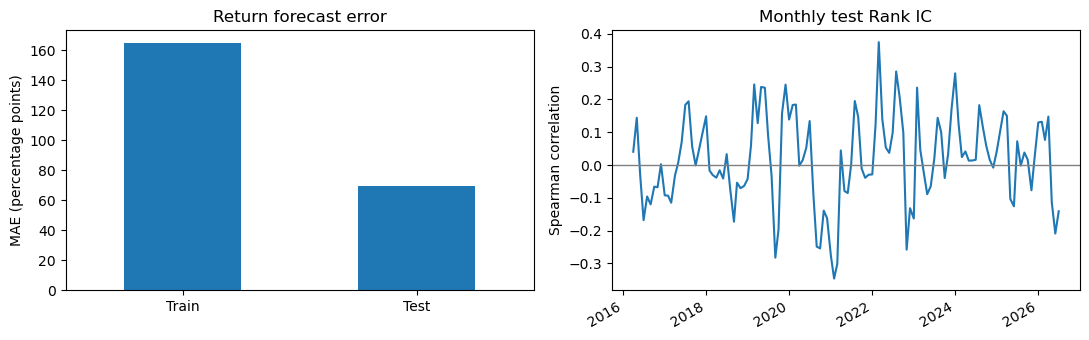

,Top picks (%),Pool (%),Difference (pp),Picks with returns,Pool with returns
entry,,,,,
2016-04-01,16.762,3.275,13.487,9,1914
2016-05-02,11.378,5.687,5.691,10,1919
2016-06-01,-2.690,6.504,-9.193,10,1925
2016-07-01,7.535,6.620,0.916,10,1932
2016-08-01,-8.626,-1.343,-7.284,10,1941
2016-09-01,-7.339,5.893,-13.232,10,1948
2016-10-03,9.009,8.603,0.406,10,1941
2016-11-01,21.071,13.579,7.492,10,1949
2016-12-01,33.651,8.730,24.921,10,1958


In [13]:
from sklearn.metrics import mean_absolute_error, r2_score

train = development_samples(panel)
test = panel.loc[panel.entry.between(START, END) & panel.target.notna()].copy()

forecast_metrics = {}
for name, sample in [("Train", train), ("Test", test)]:
    actual = sample.target
    forecast = final_model.predict(sample[FEATURES])
    forecast_metrics[name] = {
        "MAE (percentage points)": 100 * mean_absolute_error(actual, forecast),
        "RMSE (percentage points)": 100 * np.sqrt(np.mean((forecast - actual) ** 2)),
        "R²": r2_score(actual, forecast),
        "Direction accuracy (%)": 100 * ((forecast > 0) == (actual > 0)).mean(),
        "Always-up baseline (%)": 100 * actual.gt(0).mean(),
    }
accuracy = pd.DataFrame(forecast_metrics).T
display(accuracy.round(3))

test["forecast"] = final_model.predict(test[FEATURES])
rank_ic = test.groupby("entry")[["target", "forecast"]].corr(method="spearman")
rank_ic = rank_ic.xs("forecast", level=1).target
print(f"Mean monthly test Rank IC: {rank_ic.mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
accuracy["MAE (percentage points)"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Return forecast error", ylabel="MAE (percentage points)")
rank_ic.plot(ax=axes[1])
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set(title="Monthly test Rank IC", ylabel="Spearman correlation", xlabel="")
fig.tight_layout()
plt.show()

# Compare the original picks with the scored pool using available returns.
selected = pd.Series(picks).rename_axis("entry").explode().rename("symbol")
is_pick = pd.MultiIndex.from_frame(test[["entry", "symbol"]]).isin(
    pd.MultiIndex.from_frame(selected.reset_index())
)
pool = test.groupby("entry").target
top = test.loc[is_pick].groupby("entry").target
monthly = pd.DataFrame(index=pd.DatetimeIndex(picks.keys(), name="entry"))
monthly["Top picks (%)"] = 100 * top.mean()
monthly["Pool (%)"] = 100 * pool.mean()
monthly["Difference (pp)"] = monthly["Top picks (%)"] - monthly["Pool (%)"]
monthly["Picks with returns"] = top.size().reindex(monthly.index, fill_value=0)
monthly["Pool with returns"] = pool.size().reindex(monthly.index, fill_value=0)
print(f"Average monthly difference: {monthly['Difference (pp)'].mean():.3f} pp")
with pd.option_context("display.max_rows", None):
    display(monthly.round(3))


## 6. Simulate daily trades

In [14]:
@dataclass
class Lot:
    symbol: str
    units: float
    entry: pd.Timestamp
    due: pd.Timestamp
    mark: float
    stale: int = 0


def backtest(quotes, picks, capital=CAPITAL, fee=FEE, start=START):
    cash = capital
    nav = capital
    lots, fills, records = {}, [], []
    next_id = 0
    missing_entries = 0
    max_stale = 0
    gaps = {}
    sessions = quotes.loc[start:]
    initial_date = quotes.index[quotes.index.get_loc(sessions.index[0]) - 1]
    records.append((initial_date, cash, 0.0, nav, 0))
    for date, observed in sessions.iterrows():
        symbols = picks.get(date, [])
        # Size orders from the previous close before observing execution prices.
        budget = min(cash, nav / 3) / len(symbols) if symbols else 0
        for lot_id, lot in list(lots.items()):
            price = observed[lot.symbol]
            if pd.isna(price):
                lot.stale += 1
                max_stale = max(max_stale, lot.stale)
                if lot.stale > 5:
                    gaps[lot.symbol] = max(gaps.get(lot.symbol, 0), lot.stale)
                continue
            lot.mark, lot.stale = price, 0
            if date >= lot.due:
                notional = lot.units * price
                charge = notional * fee
                cash += notional - charge
                fills.append((date, lot_id, lot.symbol, "SELL", notional - charge, charge, lot.due))
                del lots[lot_id]
        for symbol in symbols:
            if budget <= 1e-8:
                continue
            price = observed[symbol]
            if pd.isna(price):
                missing_entries += 1
                continue
            notional = budget / (1 + fee)
            due = date + pd.Timedelta(days=90)
            lots[next_id] = Lot(symbol, notional / price, date, due, price)
            cash -= budget
            fills.append((date, next_id, symbol, "BUY", -budget, notional * fee, due))
            next_id += 1
        holdings = sum(lot.units * lot.mark for lot in lots.values())
        nav = cash + holdings
        records.append((date, cash, holdings, nav, len(lots)))
    history = pd.DataFrame(records, columns=["date", "cash", "holdings", "nav", "open_lots"]).set_index("date")
    ledger = pd.DataFrame(fills, columns=["date", "lot", "symbol", "side", "cash_change", "fee", "due"])
    changes = ledger.groupby("date").cash_change.sum().reindex(history.index, fill_value=0)
    np.testing.assert_allclose(history.cash, capital + changes.cumsum(), rtol=0, atol=1e-6)
    np.testing.assert_allclose(history.nav, history.cash + history.holdings)
    assert history.cash.min() >= -1e-7
    sales = ledger.loc[ledger.side.eq("SELL")]
    assert sales.date.ge(sales.due).all()
    return history, ledger, lots, missing_entries, max_stale, gaps

history, fills, lots, rejected, stale, gaps = backtest(quotes, picks)
history.tail()

Out[1]: 
                    cash      holdings           nav  open_lots
date                                                           
2026-09-24 -5.820766e-11  2.712136e+06  2.712136e+06         41
2026-09-25 -5.820766e-11  2.739239e+06  2.739239e+06         41
2026-09-28 -5.820766e-11  2.836808e+06  2.836808e+06         41
2026-09-29  9.831237e+05  1.879690e+06  2.862814e+06         31
2026-09-30  9.831237e+05  1.881405e+06  2.864529e+06         31


## 7. Compare portfolio performance

The S&P 500 total-return benchmark starts at the first test close. Compare cumulative returns, daily drawdown, and cash allocation. The strategy’s final NAV includes stale marks, which makes the result sensitive to the missing-price policy.

Validation RMSE: {1: np.float64(1.4564544607326162), 100: np.float64(1.4563116627338715), 1000: np.float64(1.4552301461709156)} Selected alpha: 1000
Training rows: 135394 Last training label: 2016-02-29
              Ridge strategy  S&P 500 total return
Final value     2.864529e+06          4.402747e+06
CAGR            1.054276e-01          1.516195e-01
Max drawdown   -4.833428e-01         -3.379046e-01
Sharpe          4.145136e-01          7.725008e-01
Buys: 1060 Sales: 1029
Fees: 53535.92904032121 Average cash fraction: 0.1702863304123847
Open lots: 31 Rejected entries: 0 Max stale sessions: 2624 Long gaps: {'HPY': 2624, 'HOME': 1303, 'HMHC': 1124, 'CCXI': 827, 'RXDX': 825, 'ISEE': 810, 'RETA': 755, 'IMGN': 659, 'RNA': 345, 'LBPH': 458, 'BSGM': 264, 'CDTX': 182, 'MFH': 180, 'TERN': 94}
Stale open lots: [('HPY', 2624, np.float64(35606.635137058605)), ('HOME', 1303, np.float64(96056.35810606931)), ('HMHC', 1124, np.float64(66500.98477773948)), ('HMHC', 1124, np.float64(74651.4525707770

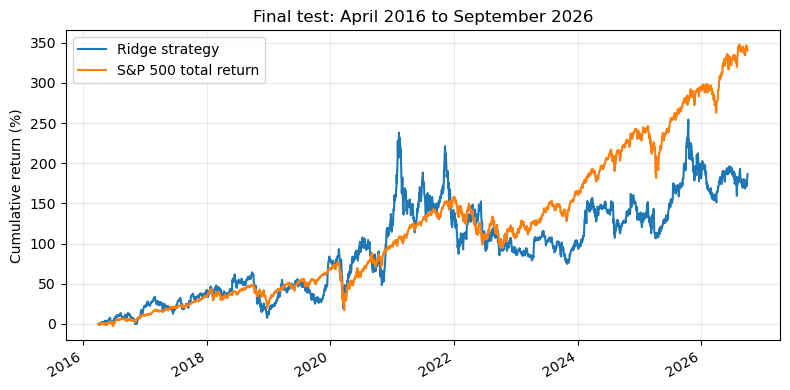

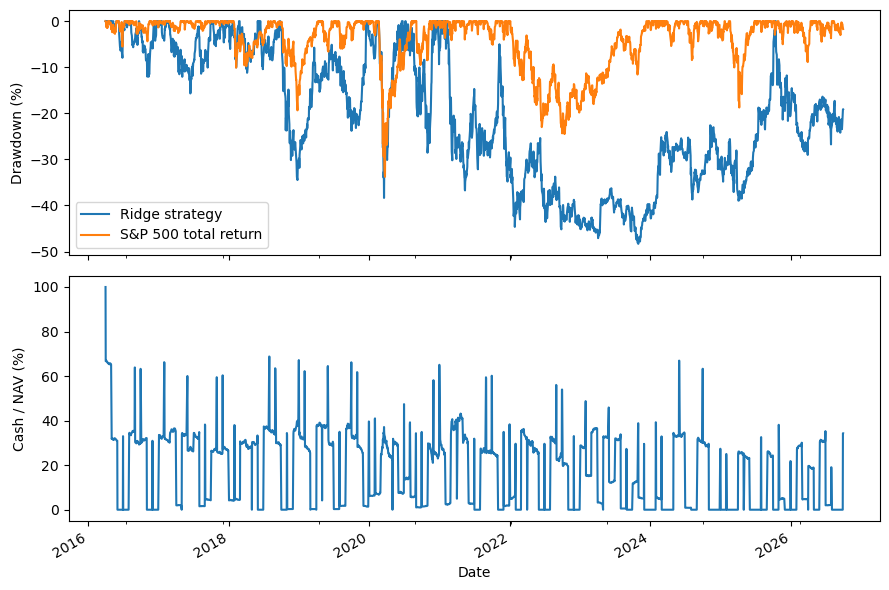

In [15]:
def performance(nav):
    years = (nav.index[-1] - nav.index[0]).days / 365.25
    returns = nav.pct_change().dropna()
    rf = 1.02 ** (1 / 252) - 1
    volatility = returns.std()
    return {
        "Final value": nav.iloc[-1],
        "CAGR": (nav.iloc[-1] / nav.iloc[0]) ** (1 / years) - 1,
        "Max drawdown": (nav / nav.cummax() - 1).min(),
        "Sharpe": np.sqrt(252) * (returns.mean() - rf) / volatility if volatility > 0 else np.nan,
    }

market = CAPITAL * benchmark.reindex(history.index) / benchmark.loc[START]
market.iloc[0] = CAPITAL
nav = pd.DataFrame({"Ridge strategy": history.nav, "S&P 500 total return": market})
metrics = pd.DataFrame({name: performance(nav[name]) for name in nav})
print("Validation RMSE:", errors, "Selected alpha:", alpha)
print("Training rows:", rows, "Last training label:", last_label.date())
print(metrics.to_string())
print("Buys:", fills.side.eq("BUY").sum(), "Sales:", fills.side.eq("SELL").sum())
print("Fees:", fills.fee.sum(), "Average cash fraction:", (history.cash / history.nav).iloc[1:].mean())
print("Open lots:", len(lots), "Rejected entries:", rejected, "Max stale sessions:", stale, "Long gaps:", gaps)
print("Stale open lots:", [(lot.symbol, lot.stale, lot.units * lot.mark) for lot in lots.values() if lot.stale])
ax = nav.div(CAPITAL).sub(1).mul(100).plot(figsize=(8, 4))
ax.set(title="Final test: April 2016 to September 2026", ylabel="Cumulative return (%)", xlabel="")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
drawdown = nav.div(nav.cummax()).sub(1).mul(100)
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
drawdown.plot(ax=axes[0])
axes[0].set(ylabel="Drawdown (%)", xlabel="")
history.cash.div(history.nav).mul(100).plot(ax=axes[1])
axes[1].set(ylabel="Cash / NAV (%)", xlabel="Date")
fig.tight_layout()
plt.show()

stale_value = sum(lot.units * lot.mark for lot in lots.values() if lot.stale)
print(f"Stale marks as share of final strategy NAV: {stale_value / history.nav.iloc[-1]:.2%}")
